In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

np.random.seed(42)
tf.random.set_seed(42)

print("Numpy:", np.__version__)
print("Pandas:", pd.__version__)
print("Tensorflow", tf.__version__)

Numpy: 2.4.2
Pandas: 3.0.1
Tensorflow 2.21.0


In [12]:
florida = pd.read_csv("florida.csv")

In [13]:
florida.head()

,Date,Avg_Temp,confidence_interval_temp,State,Country,Year,Month,Day
0,11/1/1743,17.694,2.514,Florida,United States,1743,11,1
1,12/1/1743,22.978,2.470,Florida,United States,1743,12,1
2,1/1/1744,22.978,2.470,Florida,United States,1744,1,1
3,2/1/1744,22.978,2.470,Florida,United States,1744,2,1
4,3/1/1744,22.978,2.470,Florida,United States,1744,3,1


In [14]:
florida.isna().sum()

Date                        0
Avg_Temp                    0
confidence_interval_temp    0
State                       0
Country                     0
Year                        0
Month                       0
Day                         0
dtype: int64

In [15]:
florida.dtypes

Date                            str
Avg_Temp                    float64
confidence_interval_temp    float64
State                           str
Country                         str
Year                          int64
Month                         int64
Day                           int64
dtype: object

In [16]:
florida.shape

(3239, 8)

In [17]:
florida["Date"] = pd.to_datetime(florida["Date"])
florida["Date"]

0      1743-11-01
1      1743-12-01
2      1744-01-01
3      1744-02-01
4      1744-03-01
          ...    
3234   2013-05-01
3235   2013-06-01
3236   2013-07-01
3237   2013-08-01
3238   2013-09-01
Name: Date, Length: 3239, dtype: datetime64[us]

In [18]:
florida = florida.sort_values("Date").reset_index(drop=True)

In [19]:
temperature_data = florida[["Date", "Avg_Temp"]].copy()
temperature_data.head()

,Date,Avg_Temp
0,1743-11-01,17.694
1,1743-12-01,22.978
2,1744-01-01,22.978
3,1744-02-01,22.978
4,1744-03-01,22.978


In [20]:
prediction_days = 225

train = temperature_data.iloc[:-prediction_days].copy()
test = temperature_data.iloc[-prediction_days:].copy()

In [22]:
len(train)

3014

In [23]:
len(test)

225

In [24]:
print(test["Date"].min(), "to", test["Date"].max())

1995-01-01 00:00:00 to 2013-09-01 00:00:00


In [25]:
print(train["Date"].min(), "to", train["Date"].max())

1743-11-01 00:00:00 to 1994-12-01 00:00:00


In [32]:
scaler = MinMaxScaler(feature_range=(0,1))

train_values = train["Avg_Temp"].to_numpy().reshape(-1, 1)
scaled_train = scaler.fit_transform(train_values)

In [38]:
print("Original training temperature range:",
    train["Avg_Temp"].min(), "to", train["Avg_Temp"].max())
print("Scaled training range:", scaled_train.min(), "to", scaled_train.max())
print("Scaled array shape:", scaled_train.shape)

Original training temperature range: 10.077 to 32.905
Scaled training range: 0.0 to 0.9999999999999999
Scaled array shape: (3014, 1)


In [39]:
x_train = []
y_train = []

for i in range(prediction_days, len(scaled_train)):
    x_train.append(scaled_train[i - prediction_days:i, 0])
    y_train.append(scaled_train[i, 0])

x_train = np.array(x_train)
y_train = np.array(y_train)

print("x_train shape before reshape: ", x_train.shape)
print("y_train shape: ", y_train.shape)

x_train shape before reshape:  (2789, 225)
y_train shape:  (2789,)


In [41]:
print("Number of observations in first input window:", len(x_train[0]))
print("First five scaled input values:", x_train[0][:5])
print("Scaled target for that window:", y_train[0])

print("Does the first target come immediately after the input window?", np.isclose(y_train[0], scaled_train[prediction_days, 0]))

Number of observations in first input window: 225
First five scaled input values: [0.33366918 0.5651393  0.5651393  0.5651393  0.5651393 ]
Scaled target for that window: 0.6432889434028385
Does the first target come immediately after the input window? True


In [42]:
x_train = x_train.reshape(
    x_train.shape[0],
    x_train.shape[1],
    1
)

x_train.shape

(2789, 225, 1)

In [48]:
from tensorflow.keras.layers import Input

model = Sequential()

model.add(Input(shape=(x_train.shape[1], 1)))
model.add(LSTM(units=128, activation='relu', return_sequences=True))
model.add(Dropout(0.2))
model.add(LSTM(units=128, activation='relu', return_sequences=True))
model.add(Dropout(0.2))
model.add(LSTM(units=128, activation='relu', return_sequences=False))
model.add(Dropout(0.2))
model.add(Dense(units=1)) # Prediction of the next value

In [49]:
model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                        │ (None, 225, 128)            │          66,560 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 225, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_5 (LSTM)                        │ (None, 225, 128)            │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 225, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_6 (LSTM)                        │ (None, 128)                 │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 329,857 (1.26 MB)

 Trainable params: 329,857 (1.26 MB)

 Non-trainable params: 0 (0.00 B)

In [50]:
history = model.fit(x_train, y_train, epochs=25, batch_size=32, validation_split=0.1)

Epoch 1/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 20s 220ms/step - loss: 0.0673 - val_loss: 0.0467
Epoch 2/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 220ms/step - loss: 0.0462 - val_loss: 0.0451
Epoch 3/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 215ms/step - loss: 0.0447 - val_loss: 0.0427
Epoch 4/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 213ms/step - loss: 0.0418 - val_loss: 0.0348
Epoch 5/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 214ms/step - loss: 0.0226 - val_loss: 0.0085
Epoch 6/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 215ms/step - loss: 0.0111 - val_loss: 0.0050
Epoch 7/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 214ms/step - loss: 0.0091 - val_loss: 0.0052
Epoch 8/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 217ms/step - loss: 0.0081 - val_loss: 0.0053
Epoch 9/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 221ms/step - loss: 0.0073 - val_loss: 0.0041
Epoch 10/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 217ms/step - loss: 0.0072 - val_loss: 0.0044
Epoch 11/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 219ms/step - loss: 0.0067 - val_loss: 0.0041
Epoch 12/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 17

In [51]:
actual_temp = test['Avg_Temp'].values
total_temp = pd.concat((train['Avg_Temp'], test['Avg_Temp']), axis=0)

model_inputs = total_temp[len(total_temp) - len(test) - prediction_days:].values
model_inputs = model_inputs.reshape(-1, 1)
model_inputs = scaler.transform(model_inputs)


# Make Predictions on Test Data
x_test = []

for x in range(prediction_days, len(model_inputs)):
    x_test.append(model_inputs[x - prediction_days:x, 0])

x_test = np.array(x_test)
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))

pred = model.predict(x_test)
pred = scaler.inverse_transform(pred)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step


In [52]:
# ---- Evaluate prediction performance ----
from sklearn.metrics import r2_score

pred_flat = pred.flatten()

mae = mean_absolute_error(actual_temp, pred_flat)
mse = mean_squared_error(actual_temp, pred_flat)
rmse = np.sqrt(mse)
mape = np.mean(np.abs((actual_temp - pred_flat) / actual_temp)) * 100
r2 = r2_score(actual_temp, pred_flat)

# Naive baseline: predict each month as the previous month's actual value.
# A useful model should beat this.
naive_pred = total_temp.values[len(total_temp) - len(test) - 1:-1]
naive_mae = mean_absolute_error(actual_temp, naive_pred)
naive_rmse = np.sqrt(mean_squared_error(actual_temp, naive_pred))

results = pd.DataFrame({
    "LSTM": [mae, mse, rmse, mape, r2],
    "Naive baseline": [naive_mae, naive_rmse ** 2, naive_rmse, np.nan, r2_score(actual_temp, naive_pred)],
}, index=["MAE (°C)", "MSE", "RMSE (°C)", "MAPE (%)", "R²"])

print(results.round(3))

            LSTM  Naive baseline
MAE (°C)   1.237           2.312
MSE        2.362           8.227
RMSE (°C)  1.537           2.868
MAPE (%)   5.975             NaN
R²         0.900           0.653


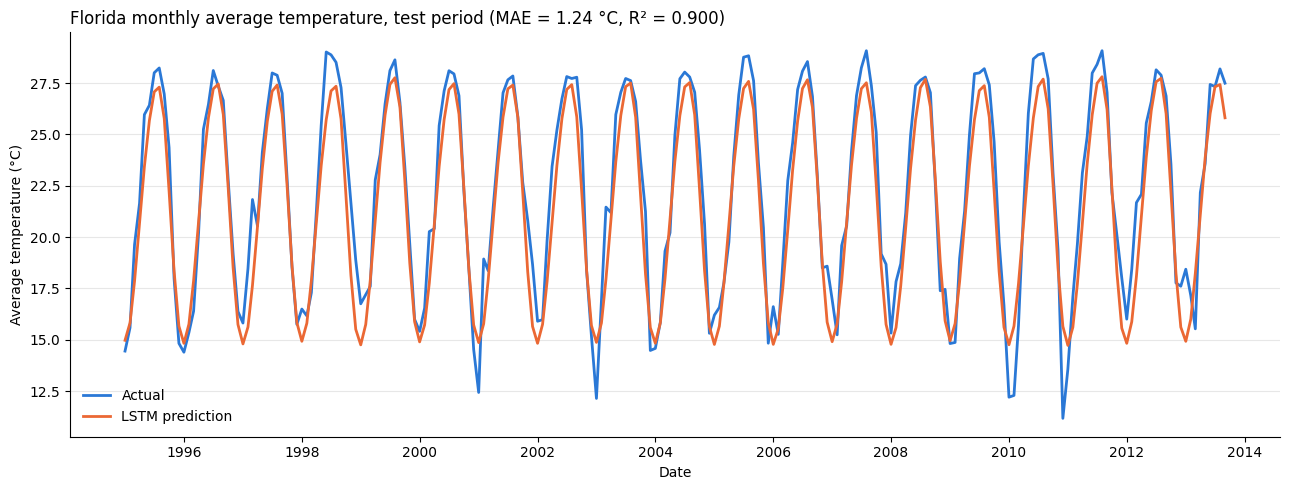

In [53]:
# ---- Visualise: actual vs predicted over time ----
ACTUAL_COLOUR = "#2a78d6"   # blue
PRED_COLOUR = "#eb6834"     # orange (colour-blind safe pair)

test_dates = test["Date"].values

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(test_dates, actual_temp, color=ACTUAL_COLOUR, linewidth=2, label="Actual")
ax.plot(test_dates, pred_flat, color=PRED_COLOUR, linewidth=2, label="LSTM prediction")

ax.set_title(f"Florida monthly average temperature, test period (MAE = {mae:.2f} °C, R² = {r2:.3f})", loc="left")
ax.set_xlabel("Date")
ax.set_ylabel("Average temperature (°C)")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

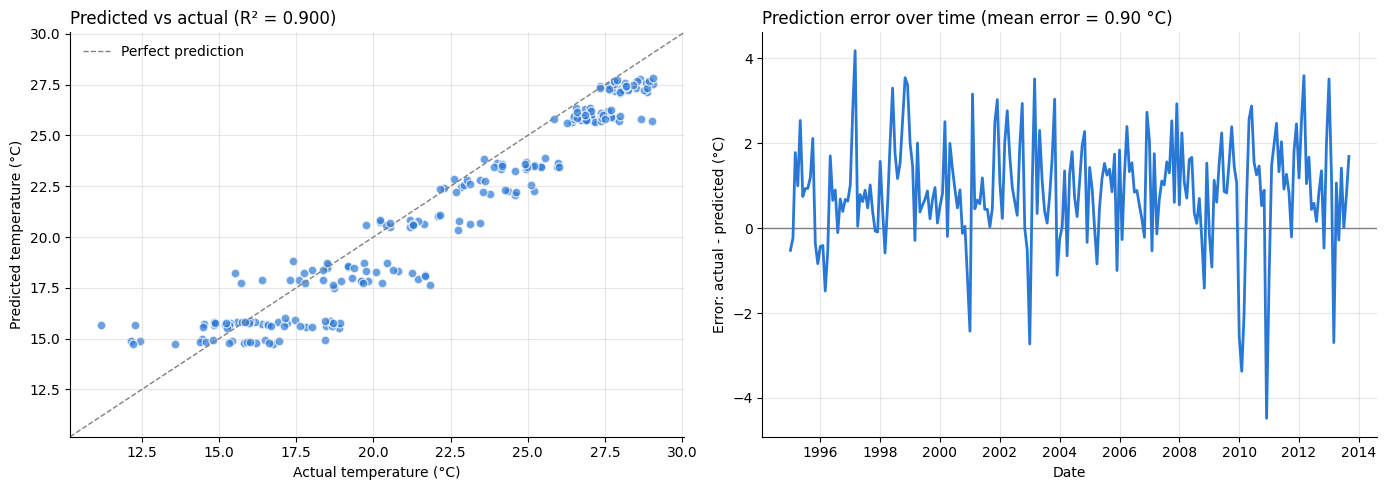

In [54]:
# ---- Visualise: prediction diagnostics ----
errors = actual_temp - pred_flat   # positive = model predicted too low

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: predicted vs actual. Points on the dashed line are perfect predictions.
lims = [min(actual_temp.min(), pred_flat.min()) - 1, max(actual_temp.max(), pred_flat.max()) + 1]
ax1.scatter(actual_temp, pred_flat, s=40, color=ACTUAL_COLOUR, alpha=0.7, edgecolor="white", linewidth=1)
ax1.plot(lims, lims, color="grey", linestyle="--", linewidth=1, label="Perfect prediction")
ax1.set_xlim(lims)
ax1.set_ylim(lims)
ax1.set_xlabel("Actual temperature (°C)")
ax1.set_ylabel("Predicted temperature (°C)")
ax1.set_title(f"Predicted vs actual (R² = {r2:.3f})", loc="left")
ax1.legend(frameon=False, loc="upper left")

# Right: error for each month. Points far from 0 are the biggest misses.
ax2.axhline(0, color="grey", linewidth=1)
ax2.plot(test_dates, errors, color=ACTUAL_COLOUR, linewidth=2)
ax2.set_xlabel("Date")
ax2.set_ylabel("Error: actual - predicted (°C)")
ax2.set_title(f"Prediction error over time (mean error = {errors.mean():.2f} °C)", loc="left")

for a in (ax1, ax2): a.grid(alpha=0.3); a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()